# Phase 6: Machine Learning Model Development

## Session 8: Baseline + Logistic Regression

**Objective:** Train classification models and identify the best-performing model.

**Leakage prevention:** Exclude `duration` because it is known only after the call.

## 1. Imports and Reproducibility

In [1]:
# ==========================================
# 1. IMPORTS AND REPRODUCIBILITY
# ==========================================

import sys
import warnings
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import imblearn

# Reproducibility
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Suppress unnecessary warnings
warnings.filterwarnings("ignore")

# Project paths
CURRENT_DIR = Path.cwd()

PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_data.csv"
IMAGE_DIR = PROJECT_ROOT / "images" / "model_development"

IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("=" * 55)
print("PHASE 6 - MODEL DEVELOPMENT")
print("=" * 55)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Imbalanced-learn:", imblearn.__version__)

print("\nProject root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Image directory:", IMAGE_DIR)
print("Random state:", RANDOM_STATE)

print("\nSetup completed successfully.")

PHASE 6 - MODEL DEVELOPMENT
Python: 3.11.13
NumPy: 2.4.6
Pandas: 3.1.0
Scikit-learn: 1.9.1
Imbalanced-learn: 0.14.2

Project root: /Users/ajeetsherkar/Bank-Marketing-ML-PBL
Dataset path: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/data/processed/cleaned_data.csv
Image directory: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/model_development
Random state: 42

Setup completed successfully.


## 2. Load and Validate Dataset

In [2]:
# ==========================================
# 2. LOAD AND VALIDATE DATASET
# ==========================================

# Load cleaned dataset
df = pd.read_csv(DATA_PATH)

# Display dataset information
print("=" * 55)
print("DATASET VALIDATION")
print("=" * 55)

print("\nDataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nTarget distribution:")
display(df["y"].value_counts())

print("\nTarget distribution (%):")
display(
    (df["y"].value_counts(normalize=True) * 100)
    .round(2)
)

# Data quality checks
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Assertions
assert df.shape == (4521, 17), "Unexpected dataset dimensions"
assert "y" in df.columns, "Target column missing"
assert df["y"].isin(["yes", "no"]).all(), "Unexpected target labels"
assert df.isnull().sum().sum() == 0, "Missing values detected"
assert not df.duplicated().any(), "Duplicate rows detected"

print("\nAll dataset validation checks passed.")

DATASET VALIDATION

Dataset shape: (4521, 17)

First five rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 826.8 KB

Target distribution:


y
no     4000
yes     521
Name: count, dtype: int64


Target distribution (%):


y
no     88.48
yes    11.52
Name: proportion, dtype: float64


Missing values: 0
Duplicate rows: 0

All dataset validation checks passed.


## 3. Separate Features and Target

In [4]:
# ==========================================
# 3. SEPARATE FEATURES AND TARGET
# ==========================================

# Separate target from predictive features
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("=" * 55)
print("FEATURE-TARGET SEPARATION")
print("=" * 55)

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nNumerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

print("\nTarget distribution:")
display(y.value_counts().rename(index={0: "no", 1: "yes"}))

print("\nTarget proportions:")
display(
    (y.value_counts(normalize=True) * 100)
    .round(2)
)

# Validation checks
assert "y" not in X.columns
assert "duration" not in X.columns
assert y.isin([0, 1]).all()
assert len(X) == len(y)
assert len(numerical_features) == 6
assert len(categorical_features) == 9
assert len(numerical_features) + len(categorical_features) == 15

print("\nFeature-target separation completed successfully.")


FEATURE-TARGET SEPARATION

Feature matrix shape: (4521, 15)
Target vector shape: (4521,)

Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Target distribution:


y
no     4000
yes     521
Name: count, dtype: int64


Target proportions:


y
0    88.48
1    11.52
Name: proportion, dtype: float64


Feature-target separation completed successfully.


## 4. Stratified Train-Validation Split

In [5]:
# ==========================================
# 4. STRATIFIED TRAIN-VALIDATION SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("=" * 55)
print("TRAIN-VALIDATION SPLIT")
print("=" * 55)

print("\nTraining features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nTraining target distribution:")
display(y_train.value_counts().rename(index={0: "no", 1: "yes"}))

print("\nValidation target distribution:")
display(y_val.value_counts().rename(index={0: "no", 1: "yes"}))

print("\nTraining positive rate:",
      round(y_train.mean() * 100, 2), "%")

print("Validation positive rate:",
      round(y_val.mean() * 100, 2), "%")

# Validation checks
assert len(X_train) == 3616
assert len(X_val) == 905
assert len(y_train) == 3616
assert len(y_val) == 905

assert abs(y_train.mean() - y_val.mean()) < 0.01

assert X_train.index.intersection(X_val.index).empty

print("\nStratified split completed successfully.")

TRAIN-VALIDATION SPLIT

Training features: (3616, 15)
Validation features: (905, 15)

Training target distribution:


y
no     3199
yes     417
Name: count, dtype: int64


Validation target distribution:


y
no     801
yes    104
Name: count, dtype: int64


Training positive rate: 11.53 %
Validation positive rate: 11.49 %

Stratified split completed successfully.


## 5. Baseline Model — Dummy Classifier

In [6]:
# ==========================================
# 5. BASELINE MODEL - DUMMY CLASSIFIER
# ==========================================

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Initialize baseline model
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train baseline
baseline_model.fit(X_train, y_train)

# Predict validation data
baseline_predictions = baseline_model.predict(X_val)

# Predicted probabilities
baseline_probabilities = baseline_model.predict_proba(X_val)[:, 1]

# Calculate metrics
baseline_metrics = {
    "Model": "Dummy Classifier",
    "Accuracy": accuracy_score(y_val, baseline_predictions),
    "Precision": precision_score(
        y_val, baseline_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, baseline_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_val, baseline_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, baseline_probabilities),
    "PR-AUC": average_precision_score(y_val, baseline_probabilities)
}

# Display results
baseline_results = pd.DataFrame([baseline_metrics])

print("=" * 55)
print("DUMMY CLASSIFIER BASELINE")
print("=" * 55)

display(baseline_results.round(4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, baseline_predictions))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        baseline_predictions,
        target_names=["No Subscription", "Subscription"],
        zero_division=0
    )
)

print("\nBaseline training and evaluation completed.")

DUMMY CLASSIFIER BASELINE


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Dummy Classifier,0.8851,0.0,0.0,0.0,0.5,0.1149



Confusion Matrix:
[[801   0]
 [104   0]]

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.89      1.00      0.94       801
   Subscription       0.00      0.00      0.00       104

       accuracy                           0.89       905
      macro avg       0.44      0.50      0.47       905
   weighted avg       0.78      0.89      0.83       905


Baseline training and evaluation completed.


## 6. Logistic Regression Pipeline

In [7]:
# ==========================================
# 6. LOGISTIC REGRESSION PIPELINE
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline as SklearnPipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from src.preprocessing import build_smotenc_model_pipeline

# Build Logistic Regression with SMOTENC preprocessing
logistic_model = build_smotenc_model_pipeline(
    estimator=LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
        class_weight=None
    ),
    random_state=RANDOM_STATE
)

print("=" * 55)
print("LOGISTIC REGRESSION PIPELINE")
print("=" * 55)

print("\nPipeline structure:")
for name, step in logistic_model.steps:
    print(f"- {name}: {type(step).__name__}")

print("\nPipeline created successfully.")

LOGISTIC REGRESSION PIPELINE

Pipeline structure:
- sampler: SMOTENC
- preprocessor: ColumnTransformer
- model: LogisticRegression

Pipeline created successfully.


## 7. Train Logistic Regression

In [8]:
# ==========================================
# 7. TRAIN LOGISTIC REGRESSION
# ==========================================

import time

print("=" * 55)
print("TRAINING LOGISTIC REGRESSION")
print("=" * 55)

start_time = time.time()

# Train complete pipeline
logistic_model.fit(X_train, y_train)

training_time = time.time() - start_time

# Generate validation predictions
logistic_predictions = logistic_model.predict(X_val)

logistic_probabilities = logistic_model.predict_proba(X_val)[:, 1]

print("\nTraining completed successfully.")
print(f"Training time: {training_time:.3f} seconds")

print("\nPrediction shape:", logistic_predictions.shape)
print("Probability shape:", logistic_probabilities.shape)

print("\nFirst 10 predictions:")
print(logistic_predictions[:10])

print("\nFirst 10 predicted probabilities:")
print(np.round(logistic_probabilities[:10], 4))

# Validate outputs
assert len(logistic_predictions) == len(y_val)
assert len(logistic_probabilities) == len(y_val)
assert np.isfinite(logistic_probabilities).all()
assert ((logistic_probabilities >= 0) &
        (logistic_probabilities <= 1)).all()

print("\nLogistic Regression training and prediction checks passed.")

TRAINING LOGISTIC REGRESSION

Training completed successfully.
Training time: 0.231 seconds

Prediction shape: (905,)
Probability shape: (905,)

First 10 predictions:
[0 0 0 0 0 0 0 0 1 0]

First 10 predicted probabilities:
[0.138  0.0162 0.2369 0.024  0.2065 0.0562 0.2032 0.4984 0.5039 0.0038]

Logistic Regression training and prediction checks passed.


## 8. Evaluation and Comparison

In [9]:
# ==========================================
# 8. EVALUATION AND COMPARISON
# ==========================================

# Calculate Logistic Regression metrics
logistic_metrics = {
    "Model": "Logistic Regression + SMOTENC",
    "Accuracy": accuracy_score(y_val, logistic_predictions),
    "Precision": precision_score(
        y_val, logistic_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, logistic_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_val, logistic_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, logistic_probabilities),
    "PR-AUC": average_precision_score(y_val, logistic_probabilities)
}

# Combine baseline and Logistic Regression
comparison_results = pd.DataFrame([
    baseline_metrics,
    logistic_metrics
])

print("=" * 65)
print("BASELINE VS LOGISTIC REGRESSION")
print("=" * 65)

display(comparison_results.round(4))

print("\nLogistic Regression Classification Report:")
print(
    classification_report(
        y_val,
        logistic_predictions,
        target_names=["No Subscription", "Subscription"],
        zero_division=0
    )
)

# Calculate improvement over baseline
print("\nPerformance changes compared with baseline:")

for metric in ["Accuracy", "Precision", "Recall", "F1-Score",
               "ROC-AUC", "PR-AUC"]:
    improvement = (
        logistic_metrics[metric] - baseline_metrics[metric]
    )
    print(f"{metric}: {improvement:+.4f}")

print("\nEvaluation completed successfully.")

BASELINE VS LOGISTIC REGRESSION


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Dummy Classifier,0.8851,0.0000,0.0000,0.0000,0.500,0.1149
1,Logistic Regression + SMOTENC,0.6707,0.1891,0.5673,0.2837,0.688,0.2899



Logistic Regression Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.92      0.68      0.79       801
   Subscription       0.19      0.57      0.28       104

       accuracy                           0.67       905
      macro avg       0.56      0.63      0.53       905
   weighted avg       0.84      0.67      0.73       905


Performance changes compared with baseline:
Accuracy: -0.2144
Precision: +0.1891
Recall: +0.5673
F1-Score: +0.2837
ROC-AUC: +0.1880
PR-AUC: +0.1749

Evaluation completed successfully.


## 9. Confusion Matrix and Visualizations

LOGISTIC REGRESSION - CONFUSION MATRIX
[[548 253]
 [ 45  59]]

True Negatives: 548
False Positives: 253
False Negatives: 45
True Positives: 59


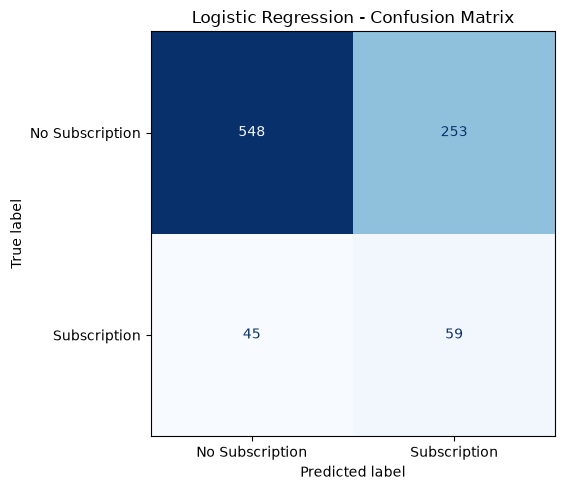

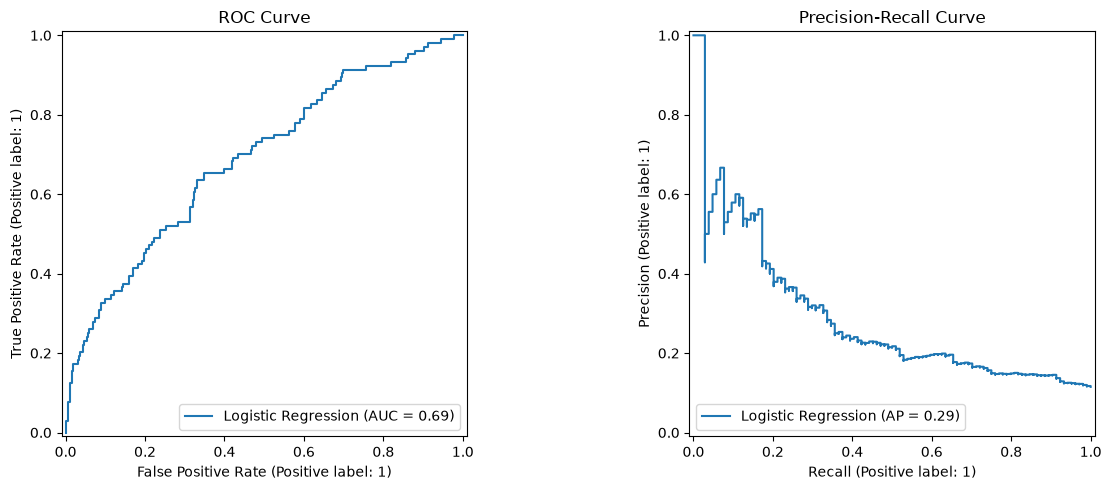


Figures saved successfully.
Image directory: /Users/ajeetsherkar/Bank-Marketing-ML-PBL/images/model_development


In [10]:
# ==========================================
# 9. CONFUSION MATRIX AND VISUALIZATIONS
# ==========================================

from sklearn.metrics import ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_val, logistic_predictions)

tn, fp, fn, tp = cm.ravel()

print("=" * 55)
print("LOGISTIC REGRESSION - CONFUSION MATRIX")
print("=" * 55)

print(cm)

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Subscription", "Subscription"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "01_logistic_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Plot ROC curve and Precision-Recall curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(
    y_val,
    logistic_probabilities,
    ax=axes[0],
    name="Logistic Regression"
)

axes[0].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_val,
    logistic_probabilities,
    ax=axes[1],
    name="Logistic Regression"
)

axes[1].set_title("Precision-Recall Curve")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "02_logistic_roc_pr_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigures saved successfully.")
print("Image directory:", IMAGE_DIR)

## 10. Observations and Business Insights

### Session 8 — Baseline and Logistic Regression Findings

**1. Baseline model**
- The Dummy Classifier achieved 88.51% accuracy by predicting every customer as a non-subscriber.
- Its precision, recall and F1-score were zero.
- This demonstrated that accuracy alone is misleading for this imbalanced dataset.

**2. Logistic Regression**
- Logistic Regression with SMOTENC achieved 67.07% accuracy.
- Precision: 18.91%.
- Recall: 56.73%.
- F1-score: 28.37%.
- ROC-AUC: 0.6880.
- PR-AUC: 0.2899.

**3. Confusion matrix observations**
- True Positives: 59.
- True Negatives: 548.
- False Positives: 253.
- False Negatives: 45.

**4. Business insights**
- The model identified 59 of 104 actual subscribers.
- Its recall is substantially better than the Dummy Classifier.
- High false positives may increase unnecessary campaign contact costs.
- Missed subscribers represent potential lost conversion opportunities.

**5. Conclusion**

Logistic Regression is a useful first predictive model and substantially improves subscriber identification over the majority-class baseline. However, its low precision and moderate recall indicate that further model development, cross-validation and hyperparameter tuning are necessary before selecting a final model.

**Status:** Baseline and Logistic Regression completed. Final model selection is deferred until all five algorithms have been evaluated.

## Session 9: Decision Tree and Random Forest

**Objective:** Train two tree-based classification algorithms using the existing leakage-safe SMOTENC preprocessing pipeline.

**Algorithms:**
1. Decision Tree Classifier
2. Random Forest Classifier

**Evaluation:** Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC.

In [11]:
# ==========================================
# SESSION 9 - TREE-BASED MODELS
# ==========================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd
import time

print("=" * 60)
print("SESSION 9 - DECISION TREE AND RANDOM FOREST")
print("=" * 60)

# ------------------------------------------
# 1. Create Decision Tree pipeline
# ------------------------------------------

decision_tree_pipeline = build_smotenc_model_pipeline(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    random_state=42
)

# ------------------------------------------
# 2. Create Random Forest pipeline
# ------------------------------------------

random_forest_pipeline = build_smotenc_model_pipeline(
    estimator=RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    random_state=42
)

print("\nBoth model pipelines created successfully.")

# ------------------------------------------
# 3. Train Decision Tree
# ------------------------------------------

start_time = time.time()

decision_tree_pipeline.fit(X_train, y_train)

decision_tree_training_time = time.time() - start_time

decision_tree_predictions = decision_tree_pipeline.predict(X_val)

decision_tree_probabilities = (
    decision_tree_pipeline.predict_proba(X_val)[:, 1]
)

print("\nDecision Tree training completed.")
print("Training time:", round(decision_tree_training_time, 3), "seconds")

# ------------------------------------------
# 4. Train Random Forest
# ------------------------------------------

start_time = time.time()

random_forest_pipeline.fit(X_train, y_train)

random_forest_training_time = time.time() - start_time

random_forest_predictions = random_forest_pipeline.predict(X_val)

random_forest_probabilities = (
    random_forest_pipeline.predict_proba(X_val)[:, 1]
)

print("\nRandom Forest training completed.")
print("Training time:", round(random_forest_training_time, 3), "seconds")

# ------------------------------------------
# 5. Evaluation function
# ------------------------------------------

def evaluate_model(name, y_true, predictions, probabilities):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities)
    }

# ------------------------------------------
# 6. Compare both models with Logistic Regression
# ------------------------------------------

decision_tree_results = evaluate_model(
    "Decision Tree",
    y_val,
    decision_tree_predictions,
    decision_tree_probabilities
)

random_forest_results = evaluate_model(
    "Random Forest",
    y_val,
    random_forest_predictions,
    random_forest_probabilities
)

logistic_results = evaluate_model(
    "Logistic Regression + SMOTENC",
    y_val,
    logistic_predictions,
    logistic_probabilities
)

session_9_results = pd.DataFrame([
    logistic_results,
    decision_tree_results,
    random_forest_results
])

print("\n" + "=" * 60)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 60)

display(
    session_9_results.round(4)
)

print("\nSession 9 model training and evaluation completed.")

SESSION 9 - DECISION TREE AND RANDOM FOREST

Both model pipelines created successfully.

Decision Tree training completed.
Training time: 0.201 seconds

Random Forest training completed.
Training time: 0.45 seconds

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression + SMOTENC,0.6707,0.1891,0.5673,0.2837,0.6880,0.2899
1,Decision Tree,0.7713,0.2275,0.4135,0.2935,0.6156,0.1615
2,Random Forest,0.8166,0.2687,0.3462,0.3025,0.6979,0.2673



Session 9 model training and evaluation completed.



DECISION TREE
[[655 146]
 [ 61  43]]
True Negatives: 655
False Positives: 146
False Negatives: 61
True Positives: 43

RANDOM FOREST
[[703  98]
 [ 68  36]]
True Negatives: 703
False Positives: 98
False Negatives: 68
True Positives: 36


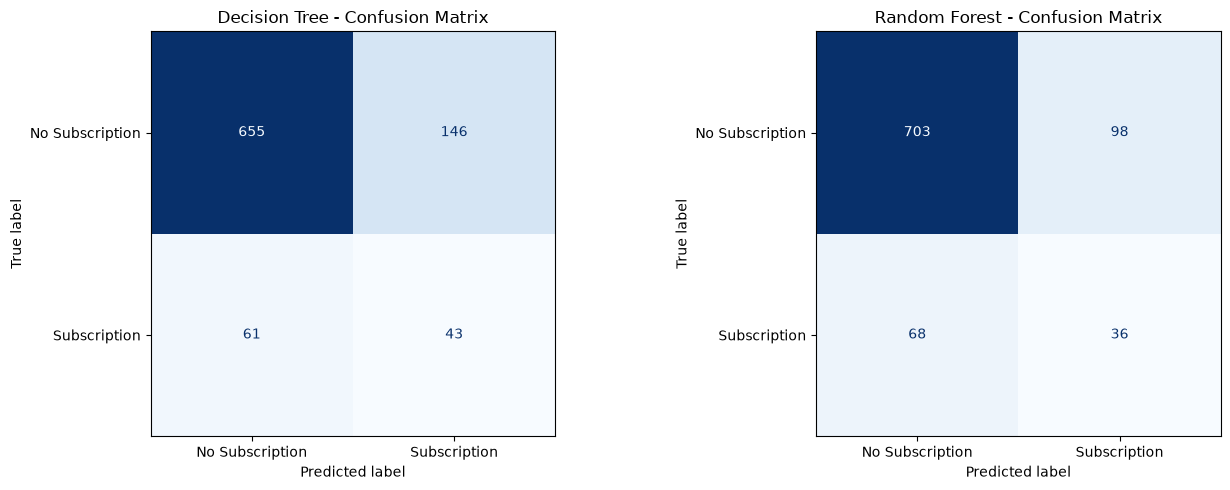


Confusion matrix figure saved successfully.


In [12]:
# ==========================================
# SESSION 9 - CONFUSION MATRICES
# ==========================================

from sklearn.metrics import ConfusionMatrixDisplay

models_to_visualize = {
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (model_name, predictions) in zip(
    axes,
    models_to_visualize.items()
):

    cm = confusion_matrix(y_val, predictions)

    tn, fp, fn, tp = cm.ravel()

    print("\n" + "=" * 50)
    print(model_name.upper())
    print("=" * 50)

    print(cm)
    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Subscription", "Subscription"]
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "03_tree_models_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nConfusion matrix figure saved successfully.")

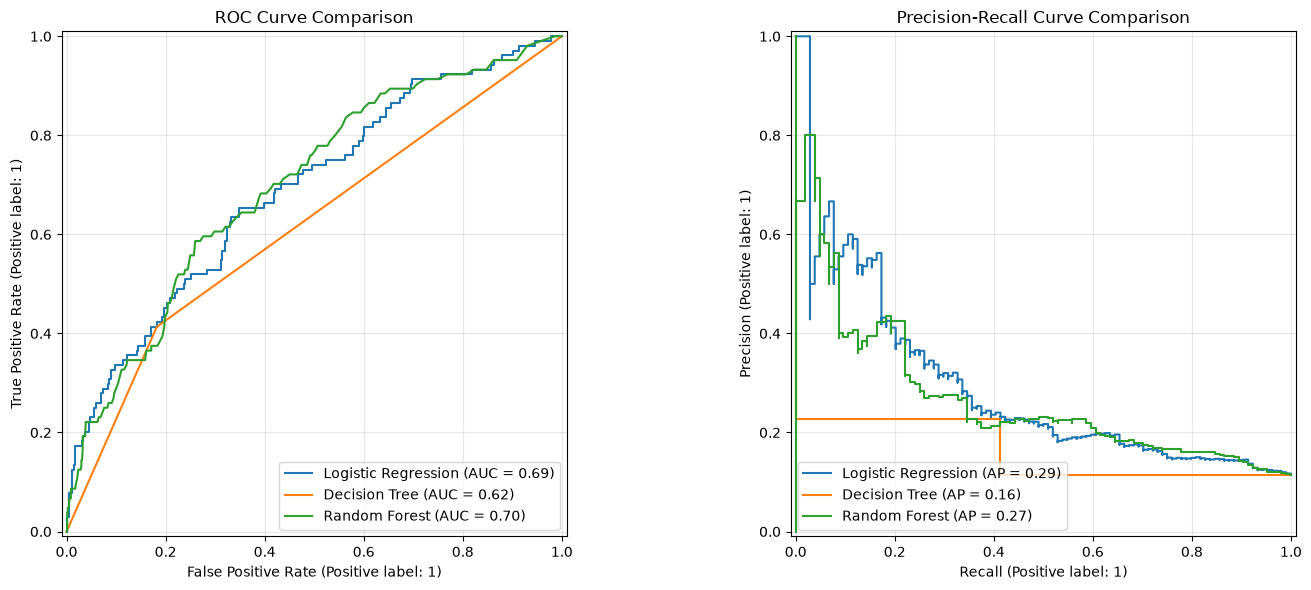

ROC and PR comparison figures saved successfully.


In [13]:
# ==========================================
# SESSION 9 - ROC AND PR CURVE COMPARISON
# ==========================================

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# Model probabilities
model_probabilities = {
    "Logistic Regression": logistic_probabilities,
    "Decision Tree": decision_tree_probabilities,
    "Random Forest": random_forest_probabilities
}

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ROC curves
for model_name, probabilities in model_probabilities.items():

    RocCurveDisplay.from_predictions(
        y_val,
        probabilities,
        name=model_name,
        ax=axes[0]
    )

axes[0].set_title("ROC Curve Comparison")
axes[0].grid(alpha=0.3)

# Precision-Recall curves
for model_name, probabilities in model_probabilities.items():

    PrecisionRecallDisplay.from_predictions(
        y_val,
        probabilities,
        name=model_name,
        ax=axes[1]
    )

axes[1].set_title("Precision-Recall Curve Comparison")
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "04_model_roc_pr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC and PR comparison figures saved successfully.")

RANDOM FOREST - FEATURE IMPORTANCE


,Feature,Importance
0,num__balance,0.14726
1,num__day,0.09818
2,num__age,0.08861
3,cat__contact_cellular,0.06310
4,num__campaign,0.05399
5,cat__contact_unknown,0.05163
6,num__pdays,0.05112
7,cat__loan_no,0.02512
8,cat__loan_yes,0.02448
9,cat__housing_no,0.02334


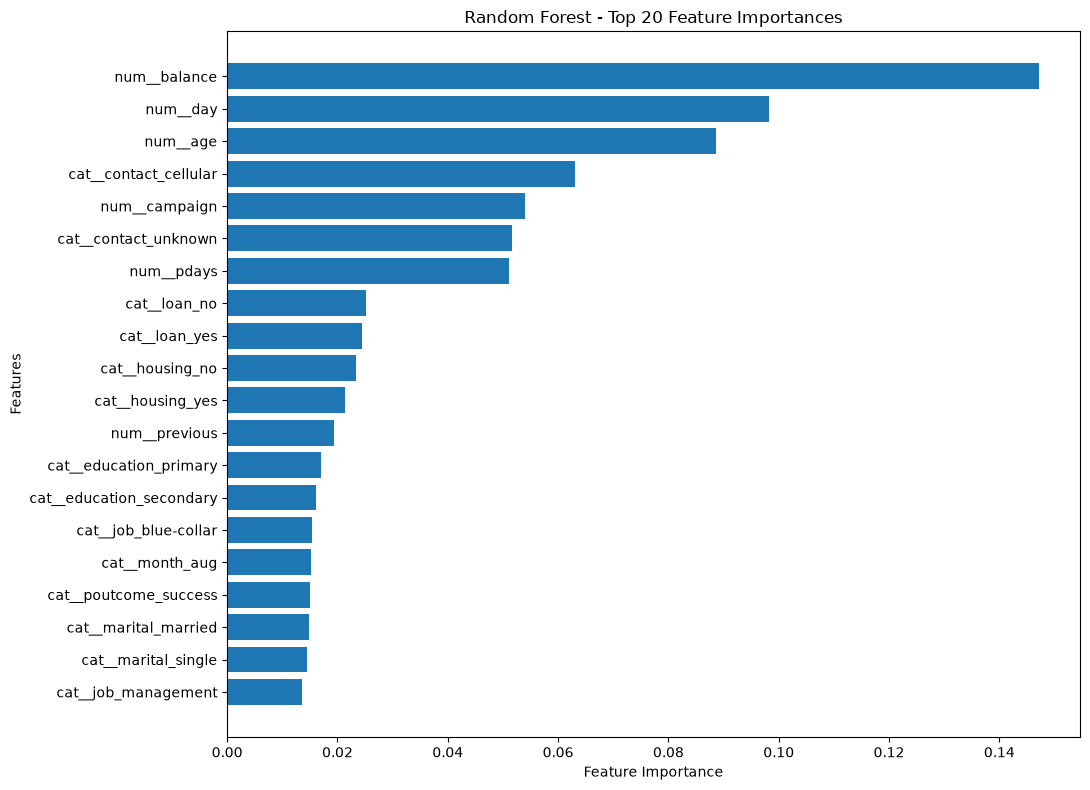


Feature importance figure saved successfully.


In [14]:
# ==========================================
# SESSION 9 - RANDOM FOREST FEATURE IMPORTANCE
# ==========================================

# Access fitted preprocessing and Random Forest
fitted_preprocessor = random_forest_pipeline.named_steps[
    "preprocessor"
]

fitted_random_forest = random_forest_pipeline.named_steps[
    "model"
]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract feature importance
importance_values = fitted_random_forest.feature_importances_

# Create importance DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("RANDOM FOREST - FEATURE IMPORTANCE")
print("=" * 60)

display(feature_importance_df.head(20).round(5))

# Plot top 20 features
top_features = feature_importance_df.head(20).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Random Forest - Top 20 Feature Importances")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "05_random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFeature importance figure saved successfully.")

### Session 9 — Random Forest Feature Importance: Observations and Business Insights

**Observations**
1. Balance is the most influential feature, with an importance score of 0.14726.
2. Day and age are the second and third most important features.
3. Contact type, campaign, and previous-contact information also contribute to the model.
4. Loan and housing categories appear among the top 20 features.
5. Feature importance values represent the Random Forest model's impurity-based contribution and should not be interpreted as causal effects.

**Business Insights**
1. Customer financial information may help prioritize potential subscribers.
2. Customer age can support further analysis of different customer segments.
3. Contact type and campaign history may help improve campaign planning.
4. The bank should evaluate these patterns alongside campaign cost and customer response rates.

**Conclusion**

Balance, day, age, contact type, and campaign-related variables are among the strongest features in the current Random Forest model. These findings provide useful directions for further investigation, but they do not establish causation or determine the final feature set.

**Status:** Random Forest feature-importance analysis completed. Further model evaluation and validation are required.

## Session 10 — Support Vector Machine and Gradient Boosting

This session introduces two additional classification algorithms:

1. Support Vector Machine (SVM)
2. Gradient Boosting Classifier

Both models use the existing leakage-safe SMOTENC preprocessing pipeline and the same stratified train-validation split. Their performance will be evaluated using Accuracy, Precision, Recall, F1-Score, ROC-AUC, and PR-AUC.

In [15]:
# ==========================================
# SESSION 10 - SVM AND GRADIENT BOOSTING
# ==========================================

from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier
import time

print("=" * 60)
print("SESSION 10 - SVM AND GRADIENT BOOSTING")
print("=" * 60)

# ------------------------------------------
# 1. Create SVM pipeline
# ------------------------------------------

svm_pipeline = build_smotenc_model_pipeline(
    estimator=SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=RANDOM_STATE
    ),
    random_state=RANDOM_STATE
)

# ------------------------------------------
# 2. Create Gradient Boosting pipeline
# ------------------------------------------

gradient_boosting_pipeline = build_smotenc_model_pipeline(
    estimator=GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ),
    random_state=RANDOM_STATE
)

print("\nBoth model pipelines created successfully.")

# ------------------------------------------
# 3. Train SVM
# ------------------------------------------

start_time = time.time()

svm_pipeline.fit(X_train, y_train)

svm_training_time = time.time() - start_time

svm_predictions = svm_pipeline.predict(X_val)
svm_probabilities = svm_pipeline.predict_proba(X_val)[:, 1]

print("\nSVM training completed.")
print("Training time:", round(svm_training_time, 3), "seconds")

# ------------------------------------------
# 4. Train Gradient Boosting
# ------------------------------------------

start_time = time.time()

gradient_boosting_pipeline.fit(X_train, y_train)

gradient_boosting_training_time = time.time() - start_time

gradient_boosting_predictions = (
    gradient_boosting_pipeline.predict(X_val)
)

gradient_boosting_probabilities = (
    gradient_boosting_pipeline.predict_proba(X_val)[:, 1]
)

print("\nGradient Boosting training completed.")
print(
    "Training time:",
    round(gradient_boosting_training_time, 3),
    "seconds"
)

# ------------------------------------------
# 5. Validate predictions
# ------------------------------------------

for model_name, predictions, probabilities in [
    ("SVM", svm_predictions, svm_probabilities),
    (
        "Gradient Boosting",
        gradient_boosting_predictions,
        gradient_boosting_probabilities
    )
]:
    assert len(predictions) == len(y_val)
    assert len(probabilities) == len(y_val)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

    print(f"\n{model_name} prediction checks passed.")

print("\nSession 10 model training completed successfully.")

SESSION 10 - SVM AND GRADIENT BOOSTING

Both model pipelines created successfully.

SVM training completed.
Training time: 3.634 seconds

Gradient Boosting training completed.
Training time: 0.779 seconds

SVM prediction checks passed.

Gradient Boosting prediction checks passed.

Session 10 model training completed successfully.


In [16]:
# ==========================================
# SESSION 10 - MODEL EVALUATION AND COMPARISON
# ==========================================

# Evaluate SVM
svm_results = evaluate_model(
    "SVM",
    y_val,
    svm_predictions,
    svm_probabilities
)

# Evaluate Gradient Boosting
gradient_boosting_results = evaluate_model(
    "Gradient Boosting",
    y_val,
    gradient_boosting_predictions,
    gradient_boosting_probabilities
)

# Combine results from all five algorithms
session_10_results = pd.DataFrame([
    logistic_results,
    decision_tree_results,
    random_forest_results,
    svm_results,
    gradient_boosting_results
])

# Display comparison
print("=" * 75)
print("SESSION 10 - FIVE MODEL PERFORMANCE COMPARISON")
print("=" * 75)

display(
    session_10_results
    .set_index("Model")
    .round(4)
)

# Identify the best model for each metric
print("\nBEST MODEL BY METRIC")
print("=" * 50)

for metric in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]:
    best_index = session_10_results[metric].idxmax()
    best_model = session_10_results.loc[best_index, "Model"]
    best_score = session_10_results.loc[best_index, metric]

    print(f"{metric}: {best_model} ({best_score:.4f})")

print("\nFive-model evaluation completed successfully.")

SESSION 10 - FIVE MODEL PERFORMANCE COMPARISON


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression + SMOTENC,0.6707,0.1891,0.5673,0.2837,0.6880,0.2899
Decision Tree,0.7713,0.2275,0.4135,0.2935,0.6156,0.1615
Random Forest,0.8166,0.2687,0.3462,0.3025,0.6979,0.2673
SVM,0.7503,0.2202,0.4615,0.2981,0.6879,0.2378
Gradient Boosting,0.7403,0.2282,0.5288,0.3188,0.7221,0.3102



BEST MODEL BY METRIC
Accuracy: Random Forest (0.8166)
Precision: Random Forest (0.2687)
Recall: Logistic Regression + SMOTENC (0.5673)
F1-Score: Gradient Boosting (0.3188)
ROC-AUC: Gradient Boosting (0.7221)
PR-AUC: Gradient Boosting (0.3102)

Five-model evaluation completed successfully.



Logistic Regression
True Negatives: 548
False Positives: 253
False Negatives: 45
True Positives: 59

Decision Tree
True Negatives: 655
False Positives: 146
False Negatives: 61
True Positives: 43

Random Forest
True Negatives: 703
False Positives: 98
False Negatives: 68
True Positives: 36

SVM
True Negatives: 631
False Positives: 170
False Negatives: 56
True Positives: 48

Gradient Boosting
True Negatives: 615
False Positives: 186
False Negatives: 49
True Positives: 55


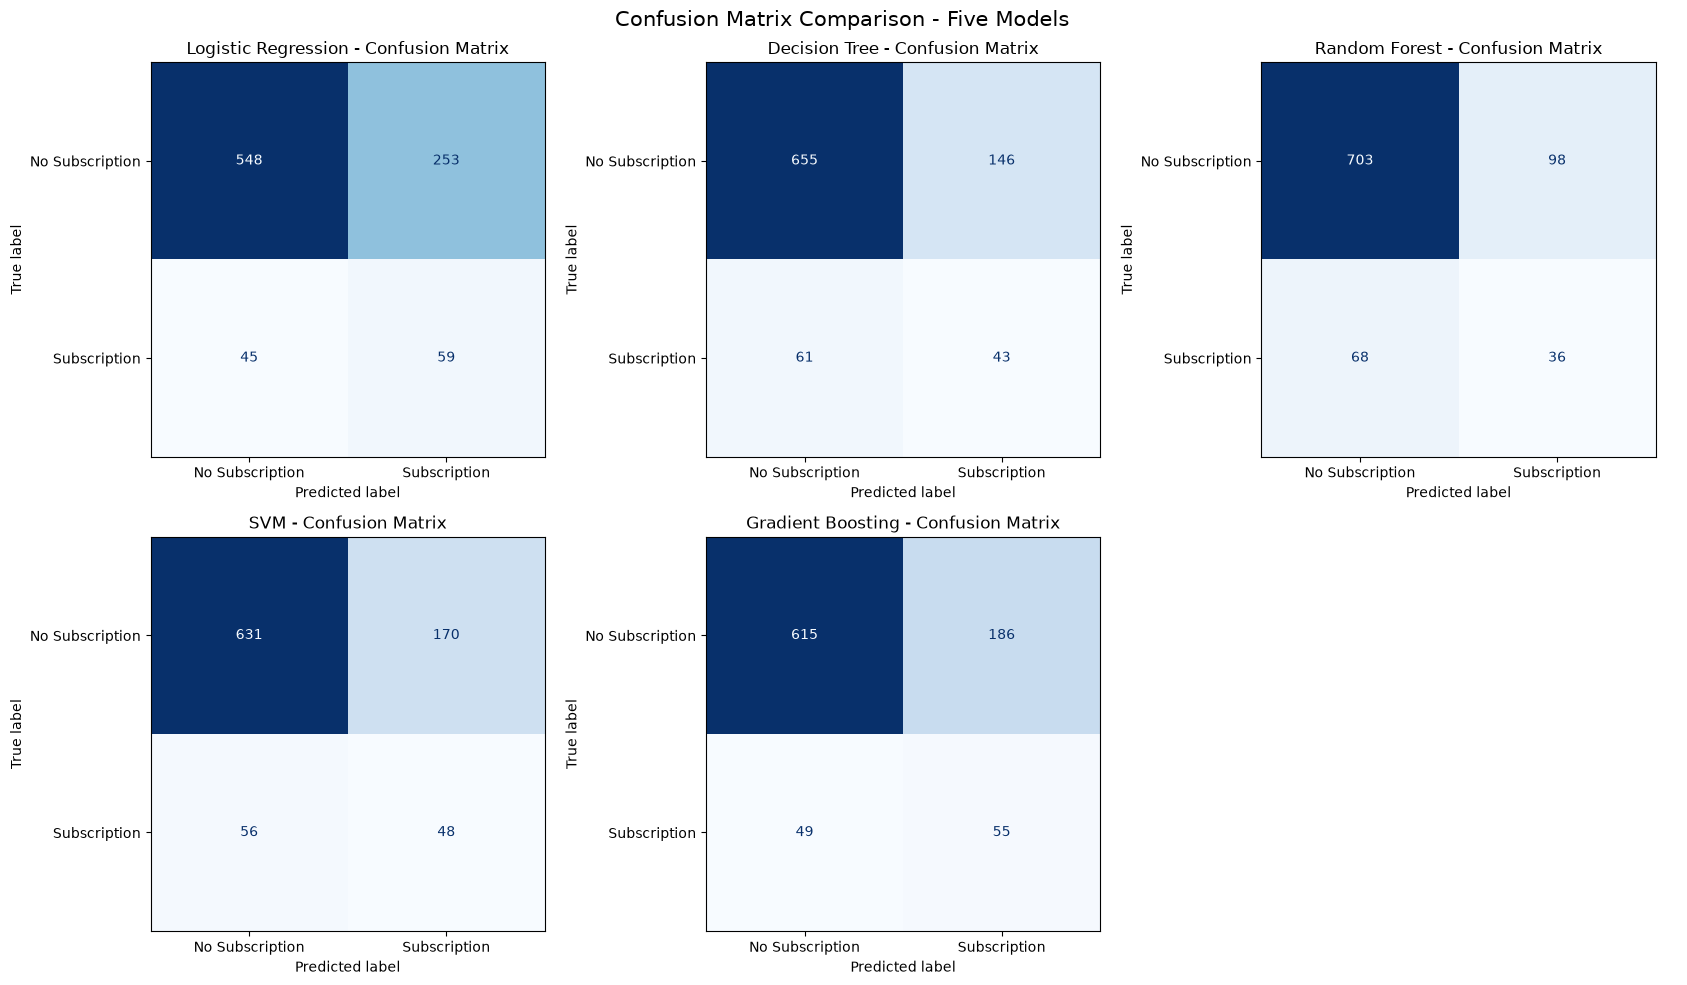


Confusion matrix comparison saved successfully.


In [17]:
# ==========================================
# SESSION 10 - CONFUSION MATRIX COMPARISON
# ==========================================

from sklearn.metrics import ConfusionMatrixDisplay

models_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": decision_tree_predictions,
    "Random Forest": random_forest_predictions,
    "SVM": svm_predictions,
    "Gradient Boosting": gradient_boosting_predictions
}

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

axes = axes.flatten()

for ax, (model_name, predictions) in zip(
    axes, models_predictions.items()
):
    cm = confusion_matrix(y_val, predictions)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Subscription", "Subscription"]
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"{model_name} - Confusion Matrix")

    tn, fp, fn, tp = cm.ravel()

    print(f"\n{model_name}")
    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)

# Hide unused sixth subplot
axes[-1].axis("off")

plt.suptitle(
    "Confusion Matrix Comparison - Five Models",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "06_five_model_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nConfusion matrix comparison saved successfully.")

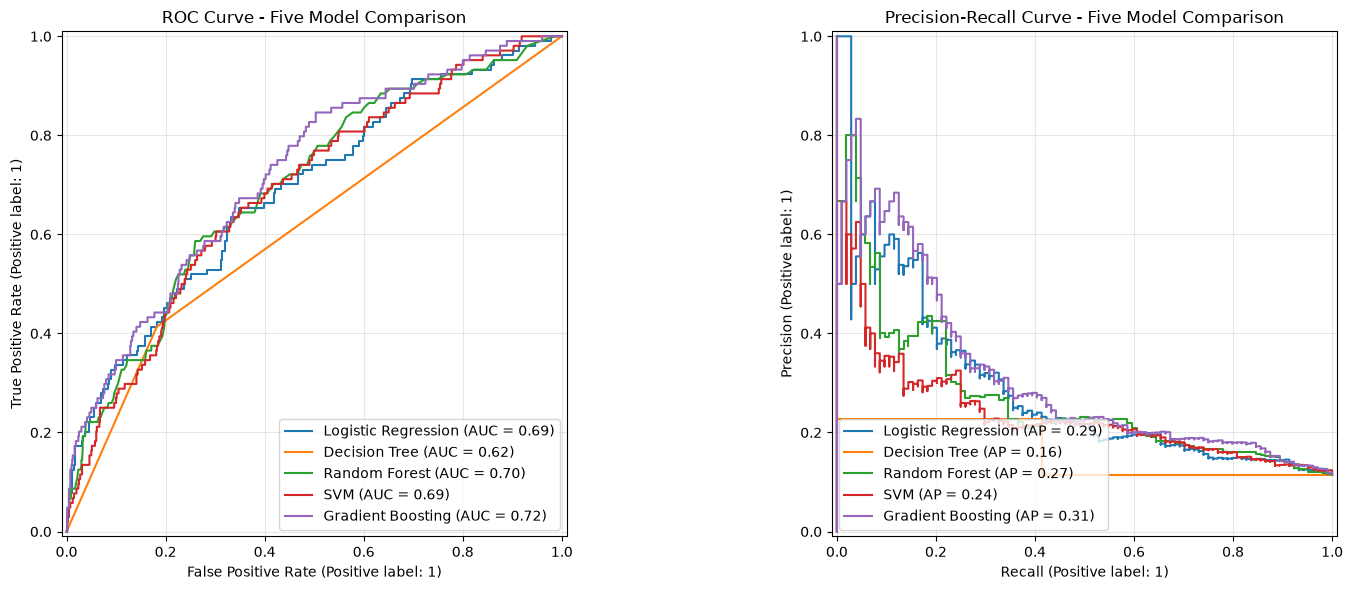


ROC and PR comparison saved successfully.


In [18]:
# ==========================================
# SESSION 10 - ROC AND PR CURVE COMPARISON
# ==========================================

from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

model_probabilities = {
    "Logistic Regression": logistic_probabilities,
    "Decision Tree": decision_tree_probabilities,
    "Random Forest": random_forest_probabilities,
    "SVM": svm_probabilities,
    "Gradient Boosting": gradient_boosting_probabilities
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC curves
for model_name, probabilities in model_probabilities.items():

    RocCurveDisplay.from_predictions(
        y_val,
        probabilities,
        name=model_name,
        ax=axes[0]
    )

axes[0].set_title("ROC Curve - Five Model Comparison")
axes[0].grid(alpha=0.3)

# Precision-Recall curves
for model_name, probabilities in model_probabilities.items():

    PrecisionRecallDisplay.from_predictions(
        y_val,
        probabilities,
        name=model_name,
        ax=axes[1]
    )

axes[1].set_title("Precision-Recall Curve - Five Model Comparison")
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "07_five_model_roc_pr_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nROC and PR comparison saved successfully.")

## Session 10 — Model Comparison: Observations and Business Insights

### 1. Model Performance Observations

Five classification algorithms were evaluated using the same stratified train-validation split and SMOTENC preprocessing pipeline.

- **Logistic Regression:** Achieved the highest recall of 0.5673, identifying the largest proportion of actual subscribers. However, it produced 253 false positives.
- **Decision Tree:** Achieved an F1-score of 0.2935, but its ROC-AUC of 0.6156 was the lowest among the five models.
- **Random Forest:** Achieved the highest accuracy (0.8166) and precision (0.2687). However, its recall was comparatively low at 0.3462.
- **Support Vector Machine (SVM):** Achieved a recall of 0.4615 and an F1-score of 0.2981, providing intermediate performance.
- **Gradient Boosting:** Achieved the highest F1-score (0.3188), ROC-AUC (0.7221), and PR-AUC (0.3102), making it the strongest overall candidate in this initial comparison.

### 2. Confusion Matrix Observations

The confusion matrices provide additional insight into the classification performance:

- Logistic Regression identified 59 actual subscribers but generated 253 false positives.
- Decision Tree identified 43 actual subscribers and generated 146 false positives.
- Random Forest correctly identified 36 subscribers and generated only 98 false positives.
- SVM correctly identified 48 subscribers with 170 false positives.
- Gradient Boosting correctly identified 55 subscribers, missed 49 subscribers, and generated 186 false positives.

### 3. ROC and Precision-Recall Analysis

- Gradient Boosting achieved the highest ROC-AUC of 0.7221, indicating the strongest ranking performance among the evaluated models.
- Gradient Boosting also achieved the highest PR-AUC of 0.3102, which is particularly useful for evaluating performance on this imbalanced dataset.
- Random Forest achieved the highest accuracy, but accuracy alone is insufficient for selecting a model.
- The Precision-Recall curves demonstrate that identifying the minority subscription class remains challenging.

### 4. Business Insights

The objective of the Bank Marketing project is to identify customers who are more likely to subscribe to a term deposit.

- High recall can help identify more potential subscribers and reduce missed marketing opportunities.
- High precision can reduce unnecessary calls to customers who are unlikely to subscribe.
- False positives can increase campaign costs because marketing resources are spent contacting customers who do not subscribe.
- False negatives represent potential subscribers who are missed by the prediction system.
- Gradient Boosting currently provides the strongest balance of precision and recall based on its F1-score.

### 5. Initial Conclusion

Based on the initial validation results, Gradient Boosting is the most promising candidate because it achieved the highest F1-score, ROC-AUC, and PR-AUC among the five evaluated algorithms.

However, this is not the final model selection. Further cross-validation and hyperparameter tuning will be performed in the next sessions before selecting the final model.

**Session 10 Status:** SVM and Gradient Boosting training, evaluation, confusion matrix analysis, and ROC/PR curve comparison completed successfully.

## Session 11 — Cross-Validation, Hyperparameter Tuning and Final Model Comparison

### Objectives

1. Evaluate all five algorithms using stratified cross-validation.
2. Identify promising models for hyperparameter tuning.
3. Optimize model parameters using RandomizedSearchCV or GridSearchCV.
4. Compare tuned models using multiple evaluation metrics.
5. Select a candidate final model based on business requirements.
6. Export the final model comparison to reports/model_comparison.csv.

All cross-validation and hyperparameter tuning will use the training dataset only. The validation dataset will be reserved for subsequent evaluation.

In [19]:
# ==========================================
# SESSION 11 - CROSS-VALIDATION SETUP
# ==========================================

from sklearn.model_selection import StratifiedKFold, cross_validate

# Five-fold stratified cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Evaluation metrics
cv_scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

# All five existing model pipelines
models_for_cv = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_pipeline,
    "Random Forest": random_forest_pipeline,
    "SVM": svm_pipeline,
    "Gradient Boosting": gradient_boosting_pipeline
}

print("=" * 65)
print("SESSION 11 - STRATIFIED CROSS-VALIDATION SETUP")
print("=" * 65)

print("\nCross-validation strategy:", cv_strategy)
print("Number of folds:", cv_strategy.n_splits)
print("Training samples:", len(X_train))
print("Validation samples reserved:", len(X_val))

print("\nEvaluation metrics:")
for metric in cv_scoring:
    print("-", metric)

# Verify class distribution in every fold
print("\nFOLD-WISE CLASS DISTRIBUTION")

for fold, (train_idx, test_idx) in enumerate(
    cv_strategy.split(X_train, y_train),
    start=1
):
    print(
        f"Fold {fold}: "
        f"Training={len(train_idx)}, "
        f"Testing={len(test_idx)}, "
        f"Positive rate={y_train.iloc[test_idx].mean():.4f}"
    )

print("\nFive-fold stratified cross-validation setup completed.")

SESSION 11 - STRATIFIED CROSS-VALIDATION SETUP

Cross-validation strategy: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Number of folds: 5
Training samples: 3616
Validation samples reserved: 905

Evaluation metrics:
- accuracy
- precision
- recall
- f1
- roc_auc
- pr_auc

FOLD-WISE CLASS DISTRIBUTION
Fold 1: Training=2892, Testing=724, Positive rate=0.1160
Fold 2: Training=2893, Testing=723, Positive rate=0.1148
Fold 3: Training=2893, Testing=723, Positive rate=0.1148
Fold 4: Training=2893, Testing=723, Positive rate=0.1148
Fold 5: Training=2893, Testing=723, Positive rate=0.1162

Five-fold stratified cross-validation setup completed.


In [20]:
# ==========================================
# SESSION 11 - FIVE-MODEL CROSS-VALIDATION
# ==========================================

import time
from sklearn.model_selection import cross_validate

cv_results = {}
cv_summary = []

print("=" * 75)
print("SESSION 11 - FIVE-MODEL CROSS-VALIDATION")
print("=" * 75)

for model_name, model_pipeline in models_for_cv.items():

    print(f"\nEvaluating: {model_name}")
    start_time = time.time()

    scores = cross_validate(
        estimator=model_pipeline,
        X=X_train,
        y=y_train,
        cv=cv_strategy,
        scoring=cv_scoring,
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    elapsed_time = time.time() - start_time

    cv_results[model_name] = scores

    result = {
        "Model": model_name,
        "Training Time (s)": round(elapsed_time, 3)
    }

    for metric in cv_scoring:

        test_scores = scores[f"test_{metric}"]
        train_scores = scores[f"train_{metric}"]

        result[f"{metric.upper()} Mean"] = test_scores.mean()
        result[f"{metric.upper()} Std"] = test_scores.std()
        result[f"Train {metric.upper()} Mean"] = train_scores.mean()

    cv_summary.append(result)

    print(f"Completed in {elapsed_time:.2f} seconds")

# Create cross-validation comparison table
cv_comparison = pd.DataFrame(cv_summary)

print("\n" + "=" * 75)
print("FIVE-MODEL CROSS-VALIDATION RESULTS")
print("=" * 75)

display(
    cv_comparison
    .set_index("Model")
    .round(4)
)

print("\nCross-validation completed successfully.")

SESSION 11 - FIVE-MODEL CROSS-VALIDATION

Evaluating: Logistic Regression
Completed in 0.88 seconds

Evaluating: Decision Tree
Completed in 0.86 seconds

Evaluating: Random Forest
Completed in 2.39 seconds

Evaluating: SVM
Completed in 17.00 seconds

Evaluating: Gradient Boosting
Completed in 3.28 seconds

FIVE-MODEL CROSS-VALIDATION RESULTS


,Training Time (s),ACCURACY Mean,ACCURACY Std,Train ACCURACY Mean,PRECISION Mean,PRECISION Std,Train PRECISION Mean,RECALL Mean,RECALL Std,Train RECALL Mean,F1 Mean,F1 Std,Train F1 Mean,ROC_AUC Mean,ROC_AUC Std,Train ROC_AUC Mean,PR_AUC Mean,PR_AUC Std,Train PR_AUC Mean
Model,,,,,,,,,,,,,,,,,,,
Logistic Regression,0.879,0.6991,0.0157,0.7043,0.1947,0.0118,0.2074,0.5133,0.0525,0.5534,0.2820,0.0180,0.3016,0.6851,0.0286,0.7122,0.2843,0.0424,0.3165
Decision Tree,0.858,0.7735,0.0128,1.0000,0.2110,0.0177,1.0000,0.3501,0.0277,1.0000,0.2630,0.0200,1.0000,0.5894,0.0151,1.0000,0.1491,0.0085,1.0000
Random Forest,2.388,0.8277,0.0081,1.0000,0.2850,0.0134,1.0000,0.3287,0.0549,1.0000,0.3036,0.0280,1.0000,0.7165,0.0229,1.0000,0.2679,0.0196,1.0000
SVM,16.998,0.7616,0.0174,0.8093,0.2227,0.0139,0.3228,0.4270,0.0526,0.5935,0.2917,0.0189,0.4181,0.6777,0.0234,0.8070,0.2403,0.0292,0.3964
Gradient Boosting,3.278,0.7497,0.0129,0.7978,0.2217,0.0129,0.3140,0.4702,0.0796,0.6331,0.3003,0.0273,0.4197,0.7050,0.0310,0.8084,0.3105,0.0402,0.4755



Cross-validation completed successfully.


In [21]:
# ==========================================
# SESSION 11 - COMPACT CV SUMMARY
# ==========================================

important_columns = [
    "Model",
    "ACCURACY Mean",
    "PRECISION Mean",
    "RECALL Mean",
    "F1 Mean",
    "ROC_AUC Mean",
    "PR_AUC Mean",
    "F1 Std",
    "PR_AUC Std"
]

cv_compact = cv_comparison[important_columns].copy()

print("=" * 75)
print("CROSS-VALIDATION SUMMARY - ALL FIVE MODELS")
print("=" * 75)

display(
    cv_compact
    .sort_values("PR_AUC Mean", ascending=False)
    .set_index("Model")
    .round(4)
)

print("\nRanking based on mean PR-AUC:")

display(
    cv_compact[
        ["Model", "PR_AUC Mean", "PR_AUC Std"]
    ]
    .sort_values("PR_AUC Mean", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

CROSS-VALIDATION SUMMARY - ALL FIVE MODELS


,ACCURACY Mean,PRECISION Mean,RECALL Mean,F1 Mean,ROC_AUC Mean,PR_AUC Mean,F1 Std,PR_AUC Std
Model,,,,,,,,
Gradient Boosting,0.7497,0.2217,0.4702,0.3003,0.7050,0.3105,0.0273,0.0402
Logistic Regression,0.6991,0.1947,0.5133,0.2820,0.6851,0.2843,0.0180,0.0424
Random Forest,0.8277,0.2850,0.3287,0.3036,0.7165,0.2679,0.0280,0.0196
SVM,0.7616,0.2227,0.4270,0.2917,0.6777,0.2403,0.0189,0.0292
Decision Tree,0.7735,0.2110,0.3501,0.2630,0.5894,0.1491,0.0200,0.0085



Ranking based on mean PR-AUC:


,Model,PR_AUC Mean,PR_AUC Std
0,Gradient Boosting,0.3105,0.0402
1,Logistic Regression,0.2843,0.0424
2,Random Forest,0.2679,0.0196
3,SVM,0.2403,0.0292
4,Decision Tree,0.1491,0.0085


## Session 11 — Cross-Validation: Observations and Findings

### 1. Cross-Validation Results

Five classification algorithms were evaluated using five-fold StratifiedKFold cross-validation on the training dataset.

- Random Forest achieved the highest mean accuracy of 0.8277.
- Random Forest achieved the highest mean precision of 0.2850.
- Logistic Regression achieved the highest mean recall of 0.5133.
- Random Forest achieved the highest mean F1-score of 0.3036.
- Random Forest achieved the highest mean ROC-AUC of 0.7165.
- Gradient Boosting achieved the highest mean PR-AUC of 0.3105.

### 2. Model Stability and Overfitting

The standard deviation of cross-validation scores provides information about model performance stability across folds.

Random Forest and Gradient Boosting show promising F1-score performance. However, the training scores indicate that tree-based models may be overfitting.

Decision Tree and Random Forest achieved perfect training scores for several metrics, while their cross-validation scores were considerably lower.

### 3. Initial Model Prioritization

Based on the cross-validation results:

- Random Forest is promising for accuracy, precision and ROC-AUC.
- Gradient Boosting is promising for PR-AUC and recall.
- Logistic Regression remains relevant when identifying more potential subscribers is important.
- SVM provides intermediate performance.
- Decision Tree requires particular attention to complexity and overfitting.

### 4. Next Steps

Hyperparameter tuning will be performed using cross-validation and the existing SMOTENC pipeline.

All five algorithms will remain part of the model comparison. Final model selection will consider cross-validation performance, validation results, model stability and business requirements.

**Session 11 Status:** Five-fold stratified cross-validation completed successfully for all five classification algorithms.

## Session 11 — Hyperparameter Tuning

RandomizedSearchCV will be used to optimize the hyperparameters of all five classification algorithms.

The primary optimization metric is Average Precision (PR-AUC), because the target variable is imbalanced.

SMOTENC will remain inside each imbalanced-learn pipeline to prevent data leakage during cross-validation.

The validation dataset will not be used during hyperparameter tuning.

In [22]:
# ==========================================
# SESSION 11 - HYPERPARAMETER SEARCH SPACES
# ==========================================

from scipy.stats import randint, loguniform

param_distributions = {

    "Logistic Regression": {
        "model__C": loguniform(0.01, 100),
        "model__class_weight": [None, "balanced"]
    },

    "Decision Tree": {
        "model__max_depth": [3, 5, 8, 10, 15, None],
        "model__min_samples_split": randint(2, 20),
        "model__min_samples_leaf": randint(1, 15),
        "model__criterion": ["gini", "entropy", "log_loss"]
    },

    "Random Forest": {
        "model__n_estimators": randint(100, 401),
        "model__max_depth": [5, 8, 12, 16, None],
        "model__min_samples_split": randint(2, 20),
        "model__min_samples_leaf": randint(1, 10),
        "model__max_features": ["sqrt", "log2"]
    },

    "SVM": {
        "model__C": loguniform(0.01, 100),
        "model__gamma": ["scale", "auto"],
        "model__kernel": ["rbf", "linear"]
    },

    "Gradient Boosting": {
        "model__n_estimators": randint(50, 301),
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_depth": randint(2, 6),
        "model__min_samples_split": randint(2, 20),
        "model__min_samples_leaf": randint(1, 10),
        "model__subsample": [0.7, 0.8, 0.9, 1.0]
    }
}

print("HYPERPARAMETER SEARCH SPACES")
print("=" * 60)

for name, parameters in param_distributions.items():
    print(f"\n{name}")
    for parameter, values in parameters.items():
        print(f"  {parameter}: {values}")

assert set(param_distributions) == set(models_for_cv)

print("\nAll five search spaces defined successfully.")

HYPERPARAMETER SEARCH SPACES

Logistic Regression
  model__C: <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x1310187d0>
  model__class_weight: [None, 'balanced']

Decision Tree
  model__max_depth: [3, 5, 8, 10, 15, None]
  model__min_samples_split: <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x131019710>
  model__min_samples_leaf: <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x136bc4650>
  model__criterion: ['gini', 'entropy', 'log_loss']

Random Forest
  model__n_estimators: <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x136bc5d50>
  model__max_depth: [5, 8, 12, 16, None]
  model__min_samples_split: <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x136bc6290>
  model__min_samples_leaf: <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x136bc55d0>
  model__max_features: ['sqrt', 'log2']

SVM
  model__C: <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x136bc60

In [23]:
# ==========================================
# SESSION 11 - RANDOMIZED HYPERPARAMETER TUNING
# ==========================================

from sklearn.model_selection import RandomizedSearchCV
import time

N_ITER = 12

tuned_models = {}
tuning_results = []

print("=" * 75)
print("SESSION 11 - RANDOMIZED HYPERPARAMETER TUNING")
print("=" * 75)

for model_name, model_pipeline in models_for_cv.items():

    print(f"\nTuning: {model_name}")
    print("-" * 60)

    search = RandomizedSearchCV(
        estimator=model_pipeline,
        param_distributions=param_distributions[model_name],
        n_iter=N_ITER,
        scoring="average_precision",
        cv=cv_strategy,
        refit=True,
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbose=1,
        error_score="raise",
        return_train_score=True
    )

    start_time = time.time()

    search.fit(X_train, y_train)

    elapsed_time = time.time() - start_time

    tuned_models[model_name] = search

    tuning_results.append({
        "Model": model_name,
        "Best CV PR-AUC": search.best_score_,
        "Tuning Time (s)": round(elapsed_time, 3),
        "Best Parameters": search.best_params_
    })

    print(f"\nBest CV PR-AUC: {search.best_score_:.4f}")
    print(f"Tuning time: {elapsed_time:.2f} seconds")
    print("Best parameters:")
    print(search.best_params_)

# Create tuning summary
tuning_summary = pd.DataFrame(tuning_results)

print("\n" + "=" * 75)
print("HYPERPARAMETER TUNING SUMMARY")
print("=" * 75)

display(
    tuning_summary[
        ["Model", "Best CV PR-AUC", "Tuning Time (s)"]
    ]
    .sort_values("Best CV PR-AUC", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

print("\nAll five hyperparameter searches completed successfully.")

SESSION 11 - RANDOMIZED HYPERPARAMETER TUNING

Tuning: Logistic Regression
------------------------------------------------------------
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best CV PR-AUC: 0.2846
Tuning time: 9.13 seconds
Best parameters:
{'model__C': np.float64(0.6071989493441299), 'model__class_weight': None}

Tuning: Decision Tree
------------------------------------------------------------
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best CV PR-AUC: 0.2366
Tuning time: 8.90 seconds
Best parameters:
{'model__criterion': 'entropy', 'model__max_depth': 8, 'model__min_samples_leaf': 7, 'model__min_samples_split': 12}

Tuning: Random Forest
------------------------------------------------------------
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best CV PR-AUC: 0.3054
Tuning time: 22.75 seconds
Best parameters:
{'model__max_depth': 8, 'model__max_features': 'log2', 'model__min_samples_leaf': 7, 'model__min_samples_split': 13, 'mo

,Model,Best CV PR-AUC,Tuning Time (s)
0,Gradient Boosting,0.3202,69.403
1,Random Forest,0.3054,22.749
2,Logistic Regression,0.2846,9.125
3,SVM,0.2597,240.884
4,Decision Tree,0.2366,8.896



All five hyperparameter searches completed successfully.


In [24]:
# ==========================================
# SESSION 11 - TUNED MODEL VALIDATION
# ==========================================

tuned_validation_results = []
tuned_validation_models = {}

print("=" * 75)
print("SESSION 11 - TUNED MODEL VALIDATION")
print("=" * 75)

for model_name, search in tuned_models.items():

    print(f"\nEvaluating tuned model: {model_name}")

    best_model = search.best_estimator_

    predictions = best_model.predict(X_val)
    probabilities = best_model.predict_proba(X_val)[:, 1]

    results = evaluate_model(
        model_name,
        y_val,
        predictions,
        probabilities
    )

    tuned_validation_results.append(results)

    tuned_validation_models[model_name] = best_model

# Create comparison table
tuned_validation_df = pd.DataFrame(
    tuned_validation_results
)

print("\nTUNED MODEL VALIDATION RESULTS")
print("=" * 75)

display(
    tuned_validation_df
    .set_index("Model")
    .round(4)
)

print("\nAll tuned models evaluated successfully.")

SESSION 11 - TUNED MODEL VALIDATION

Evaluating tuned model: Logistic Regression

Evaluating tuned model: Decision Tree

Evaluating tuned model: Random Forest

Evaluating tuned model: SVM

Evaluating tuned model: Gradient Boosting

TUNED MODEL VALIDATION RESULTS


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
Model,,,,,,
Logistic Regression,0.6707,0.1891,0.5673,0.2837,0.6882,0.2901
Decision Tree,0.6519,0.1754,0.5481,0.2657,0.6673,0.2380
Random Forest,0.6961,0.2082,0.5865,0.3073,0.7022,0.2997
SVM,0.5890,0.1763,0.7019,0.2819,0.6905,0.2492
Gradient Boosting,0.7282,0.2205,0.5385,0.3128,0.7171,0.3211



All tuned models evaluated successfully.


In [25]:
# ==========================================
# SESSION 11 - BASELINE VS TUNED COMPARISON
# ==========================================

comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

baseline_validation = session_10_results.copy()
tuned_validation = tuned_validation_df.copy()

baseline_validation = baseline_validation[
    ["Model"] + comparison_metrics
]

tuned_validation = tuned_validation[
    ["Model"] + comparison_metrics
]

baseline_vs_tuned = baseline_validation.merge(
    tuned_validation,
    on="Model",
    suffixes=("_Baseline", "_Tuned")
)

for metric in comparison_metrics:
    baseline_vs_tuned[f"{metric}_Change"] = (
        baseline_vs_tuned[f"{metric}_Tuned"]
        - baseline_vs_tuned[f"{metric}_Baseline"]
    )

print("=" * 85)
print("BASELINE VS TUNED MODEL VALIDATION COMPARISON")
print("=" * 85)

display(
    baseline_vs_tuned[
        [
            "Model",
            "F1-Score_Baseline",
            "F1-Score_Tuned",
            "F1-Score_Change",
            "PR-AUC_Baseline",
            "PR-AUC_Tuned",
            "PR-AUC_Change"
        ]
    ].round(4)
)

print("\nFULL METRIC COMPARISON")
display(baseline_vs_tuned.round(4))

print("\nBaseline versus tuned comparison completed.")

BASELINE VS TUNED MODEL VALIDATION COMPARISON


,Model,F1-Score_Baseline,F1-Score_Tuned,F1-Score_Change,PR-AUC_Baseline,PR-AUC_Tuned,PR-AUC_Change
0,Decision Tree,0.2935,0.2657,-0.0278,0.1615,0.2380,0.0765
1,Random Forest,0.3025,0.3073,0.0048,0.2673,0.2997,0.0324
2,SVM,0.2981,0.2819,-0.0163,0.2378,0.2492,0.0114
3,Gradient Boosting,0.3188,0.3128,-0.0060,0.3102,0.3211,0.0110



FULL METRIC COMPARISON


,Model,Accuracy_Baseline,Precision_Baseline,Recall_Baseline,F1-Score_Baseline,ROC-AUC_Baseline,PR-AUC_Baseline,Accuracy_Tuned,Precision_Tuned,Recall_Tuned,F1-Score_Tuned,ROC-AUC_Tuned,PR-AUC_Tuned,Accuracy_Change,Precision_Change,Recall_Change,F1-Score_Change,ROC-AUC_Change,PR-AUC_Change
0,Decision Tree,0.7713,0.2275,0.4135,0.2935,0.6156,0.1615,0.6519,0.1754,0.5481,0.2657,0.6673,0.2380,-0.1193,-0.0521,0.1346,-0.0278,0.0517,0.0765
1,Random Forest,0.8166,0.2687,0.3462,0.3025,0.6979,0.2673,0.6961,0.2082,0.5865,0.3073,0.7022,0.2997,-0.1204,-0.0605,0.2404,0.0048,0.0043,0.0324
2,SVM,0.7503,0.2202,0.4615,0.2981,0.6879,0.2378,0.5890,0.1763,0.7019,0.2819,0.6905,0.2492,-0.1613,-0.0439,0.2404,-0.0163,0.0026,0.0114
3,Gradient Boosting,0.7403,0.2282,0.5288,0.3188,0.7221,0.3102,0.7282,0.2205,0.5385,0.3128,0.7171,0.3211,-0.0122,-0.0077,0.0096,-0.0060,-0.0050,0.0110



Baseline versus tuned comparison completed.


In [26]:
# ==========================================
# SESSION 11 - CORRECTED BASELINE VS TUNED
# ==========================================

baseline_validation = session_10_results.copy()
tuned_validation = tuned_validation_df.copy()

# Normalize model names before merging
baseline_validation["Model"] = (
    baseline_validation["Model"]
    .replace({
        "Logistic Regression + SMOTENC": "Logistic Regression"
    })
)

comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

baseline_validation = baseline_validation[
    ["Model"] + comparison_metrics
]

tuned_validation = tuned_validation[
    ["Model"] + comparison_metrics
]

baseline_vs_tuned = baseline_validation.merge(
    tuned_validation,
    on="Model",
    how="inner",
    validate="one_to_one",
    suffixes=("_Baseline", "_Tuned")
)

assert len(baseline_vs_tuned) == 5
assert set(baseline_vs_tuned["Model"]) == set(models_for_cv)

for metric in comparison_metrics:
    baseline_vs_tuned[f"{metric}_Change"] = (
        baseline_vs_tuned[f"{metric}_Tuned"]
        - baseline_vs_tuned[f"{metric}_Baseline"]
    )

print("=" * 80)
print("CORRECTED FIVE-MODEL BASELINE VS TUNED COMPARISON")
print("=" * 80)

display(
    baseline_vs_tuned[
        [
            "Model",
            "F1-Score_Baseline",
            "F1-Score_Tuned",
            "F1-Score_Change",
            "PR-AUC_Baseline",
            "PR-AUC_Tuned",
            "PR-AUC_Change"
        ]
    ].round(4)
)

print("\nAll five models successfully matched.")

CORRECTED FIVE-MODEL BASELINE VS TUNED COMPARISON


,Model,F1-Score_Baseline,F1-Score_Tuned,F1-Score_Change,PR-AUC_Baseline,PR-AUC_Tuned,PR-AUC_Change
0,Logistic Regression,0.2837,0.2837,0.0000,0.2899,0.2901,0.0002
1,Decision Tree,0.2935,0.2657,-0.0278,0.1615,0.2380,0.0765
2,Random Forest,0.3025,0.3073,0.0048,0.2673,0.2997,0.0324
3,SVM,0.2981,0.2819,-0.0163,0.2378,0.2492,0.0114
4,Gradient Boosting,0.3188,0.3128,-0.0060,0.3102,0.3211,0.0110



All five models successfully matched.


In [27]:
# ==========================================
# SESSION 11 - FINAL MODEL COMPARISON REPORT
# ==========================================

from pathlib import Path
import json

# Output directory
REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Normalize baseline model names
baseline_report = session_10_results.copy()

baseline_report["Model"] = baseline_report["Model"].replace({
    "Logistic Regression + SMOTENC": "Logistic Regression"
})

# Prepare validation results
baseline_report = baseline_report.rename(columns={
    metric: f"{metric}_Baseline"
    for metric in comparison_metrics
})

tuned_report = tuned_validation_df.rename(columns={
    metric: f"{metric}_Tuned"
    for metric in comparison_metrics
})

# Prepare CV results
cv_report = cv_comparison.copy()

# Prepare tuning results
tuning_report = tuning_summary.copy()

tuning_report["Best Parameters"] = (
    tuning_report["Best Parameters"].apply(
        lambda params: json.dumps(params, default=str)
    )
)

# Merge all results
final_model_comparison = (
    baseline_report
    .merge(tuned_report, on="Model", validate="one_to_one")
    .merge(cv_report, on="Model", validate="one_to_one")
    .merge(tuning_report, on="Model", validate="one_to_one")
)

# Verify completeness
assert len(final_model_comparison) == 5
assert final_model_comparison["Model"].nunique() == 5

# Save report
report_path = REPORT_DIR / "model_comparison.csv"

final_model_comparison.to_csv(
    report_path,
    index=False
)

print("=" * 75)
print("FINAL MODEL COMPARISON REPORT")
print("=" * 75)

print(f"\nSaved successfully: {report_path}")
print(f"Total models: {len(final_model_comparison)}")
print(f"Total columns: {len(final_model_comparison.columns)}")

display(
    final_model_comparison[
        [
            "Model",
            "F1-Score_Baseline",
            "F1-Score_Tuned",
            "PR-AUC_Baseline",
            "PR-AUC_Tuned",
            "Best CV PR-AUC"
        ]
    ].round(4)
)

print("\nModel comparison CSV generated successfully.")

FINAL MODEL COMPARISON REPORT

Saved successfully: ../reports/model_comparison.csv
Total models: 5
Total columns: 35


,Model,F1-Score_Baseline,F1-Score_Tuned,PR-AUC_Baseline,PR-AUC_Tuned,Best CV PR-AUC
0,Logistic Regression,0.2837,0.2837,0.2899,0.2901,0.2846
1,Decision Tree,0.2935,0.2657,0.1615,0.2380,0.2366
2,Random Forest,0.3025,0.3073,0.2673,0.2997,0.3054
3,SVM,0.2981,0.2819,0.2378,0.2492,0.2597
4,Gradient Boosting,0.3188,0.3128,0.3102,0.3211,0.3202



Model comparison CSV generated successfully.


## Session 11 — Hyperparameter Tuning: Observations and Findings

### 1. Hyperparameter Tuning Results

RandomizedSearchCV was performed for all five classification algorithms using five-fold stratified cross-validation.

- 12 configurations were evaluated per algorithm.
- A total of 60 configurations and 300 cross-validation fits were completed.
- Average Precision (PR-AUC) was used as the primary optimization metric.
- SMOTENC remained inside the model pipelines to prevent data leakage.

### 2. Best Tuned Cross-Validation Results

| Model | Best CV PR-AUC |
|---|---:|
| Gradient Boosting | 0.3202 |
| Random Forest | 0.3054 |
| Logistic Regression | 0.2846 |
| SVM | 0.2597 |
| Decision Tree | 0.2366 |

Gradient Boosting achieved the highest tuned cross-validation PR-AUC.

### 3. Baseline vs Tuned Validation Findings

- Gradient Boosting achieved the highest tuned validation F1-score of 0.3128 and PR-AUC of 0.3211.
- Random Forest improved its validation F1-score from 0.3025 to 0.3073 and PR-AUC from 0.2673 to 0.2997.
- Logistic Regression showed almost unchanged performance.
- SVM achieved higher recall after tuning, but its F1-score decreased.
- Decision Tree improved its PR-AUC considerably, although its F1-score decreased.

### 4. Business Interpretation

The project aims to identify customers who are more likely to subscribe to a term deposit.

A higher recall can help identify more potential subscribers, while precision helps control unnecessary marketing calls.

Gradient Boosting provides the strongest overall balance based on the current F1-score, ROC-AUC and PR-AUC results.

The final model selection will also consider business requirements and the trade-off between false positives and false negatives.

### 5. Deliverables

The consolidated model comparison report was generated successfully:

`reports/model_comparison.csv`

It contains results for all five algorithms, including baseline validation metrics, tuned validation metrics, cross-validation results and selected hyperparameters.

**Session 11 Status:** Five-fold cross-validation, hyperparameter tuning, tuned model validation and consolidated model comparison completed successfully.

In [28]:
# ==========================================
# SESSION 11 - FINAL AUDIT
# ==========================================

import json
from pathlib import Path

notebook_path = Path("../notebooks/05_model_development.ipynb")
report_path = Path("../reports/model_comparison.csv")

checks = {}

# 1. Notebook exists and is valid
checks["Notebook exists"] = notebook_path.exists()

with open(notebook_path, "r", encoding="utf-8") as file:
    notebook_data = json.load(file)

checks["Notebook JSON valid"] = (
    notebook_data.get("nbformat") == 4
)

# 2. All five CV models evaluated
checks["Five CV models"] = len(cv_results) == 5

# 3. All five tuning searches completed
checks["Five tuning searches"] = len(tuned_models) == 5

# 4. All five tuned models evaluated
checks["Five validation models"] = len(tuned_validation_models) == 5

# 5. All five models in comparison
checks["Five comparison models"] = (
    len(final_model_comparison) == 5
)

# 6. Report exists
checks["Comparison CSV exists"] = report_path.exists()

# 7. CSV has correct model count
saved_report = pd.read_csv(report_path)

checks["CSV contains five models"] = (
    len(saved_report) == 5
)

# 8. No missing model names
checks["No missing model names"] = (
    saved_report["Model"].notna().all()
)

# 9. All expected algorithms present
checks["All five algorithms present"] = (
    set(saved_report["Model"]) == set(models_for_cv)
)

# 10. No notebook execution errors
execution_errors = [
    output
    for cell in notebook_data["cells"]
    if cell["cell_type"] == "code"
    for output in cell.get("outputs", [])
    if output.get("output_type") == "error"
]

checks["No notebook execution errors"] = (
    len(execution_errors) == 0
)

print("=" * 65)
print("SESSION 11 FINAL AUDIT")
print("=" * 65)

for name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")

passed_count = sum(checks.values())

print("\nAUDIT RESULT:", f"{passed_count}/{len(checks)} checks passed")

if all(checks.values()):
    print("\nSESSION 11 AUDIT PASSED")
else:
    print("\nSESSION 11 AUDIT NEEDS ATTENTION")

SESSION 11 FINAL AUDIT
[PASS] Notebook exists
[PASS] Notebook JSON valid
[PASS] Five CV models
[PASS] Five tuning searches
[PASS] Five validation models
[PASS] Five comparison models
[PASS] Comparison CSV exists
[PASS] CSV contains five models
[PASS] No missing model names
[PASS] All five algorithms present
[PASS] No notebook execution errors

AUDIT RESULT: 11/11 checks passed

SESSION 11 AUDIT PASSED
